In [1]:
# Local run: make this article's code importable (finds the folder that contains lines.py).
import pathlib
import sys

root = pathlib.Path.cwd()
while not (root / "lines.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

<div dir="rtl">

# رسم خط روی پیکسل‌ها: DDA، برزنهام و وو

نوت‌بوک همراه مقالهٔ ۱ از سری گرافیک کامپیوتری. کد کامل در `lines.py` است و اینجا قدم‌به‌قدم اجرا می‌شود.

</div>

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from lines import bresenham, dda, rasterize, rasterize_wu, wu_line

<div dir="rtl">

## DDA

روی محور بلندتر یک پیکسل یک پیکسل جلو می‌رویم و مختصات دیگر را با یک گام اعشاری جمع می‌کنیم.

</div>

In [3]:
print(dda(1, 1, 8, 6))

[(1, 1), (2, 2), (3, 2), (4, 3), (5, 4), (6, 5), (7, 5), (8, 6)]


<div dir="rtl">

## برزنهام

فقط عدد صحیح. برای همین خط، همان پیکسل‌های DDA انتخاب می‌شوند.

</div>

In [4]:
points = bresenham(1, 1, 8, 6)
print(points)
assert points == dda(1, 1, 8, 6)   # same pixels for this particular line

[(1, 1), (2, 2), (3, 2), (4, 3), (5, 4), (6, 5), (7, 5), (8, 6)]


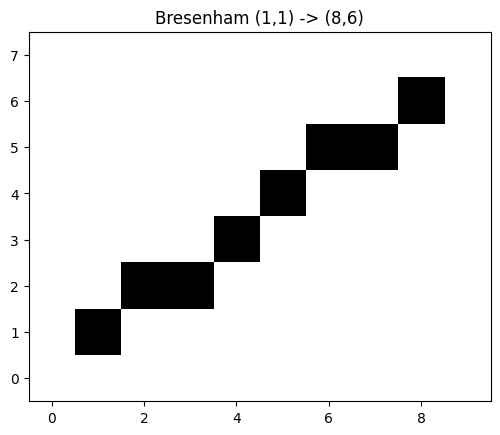

In [5]:
grid = rasterize(points, (8, 10))
plt.imshow(grid, origin="lower", cmap="gray_r")
plt.title("Bresenham (1,1) -> (8,6)")
plt.show()

<div dir="rtl">

## خطای جمع اعشاری در DDA

DDA در هر گام یک عدد اعشاری جمع می‌کند و خطای گردکردن با تعداد گام‌ها روی هم جمع می‌شود. با `float32` این خطا دیدنی است. برزنهام این منبع خطا را ندارد، چون فقط عدد صحیح به کار می‌برد.

</div>

In [6]:
step, n = np.float32(0.1), 100_000
total = np.float32(0.0)
for _ in range(n):
    total += step

print("sum of 100000 steps of 0.1 in float32:", float(total))
print("exact value:", n * 0.1)
print("accumulated error:", abs(float(total) - n * 0.1))

sum of 100000 steps of 0.1 in float32: 9998.556640625
exact value: 10000.0
accumulated error: 1.443359375


<div dir="rtl">

## ضددندانه‌شدن به روش وو

شدت روشنایی بین دو پیکسل مجاور تقسیم می‌شود. این نسخه ساده است: `x0 < x1` و شیب بین ۰ و ۱.

</div>

In [7]:
samples = wu_line(1, 1, 10, 6)
print([(x, y, round(a, 2)) for x, y, a in samples[:6]])

[(1, 1, 1.0), (1, 2, 0.0), (2, 1, 0.44), (2, 2, 0.56), (3, 2, 0.89), (3, 3, 0.11)]


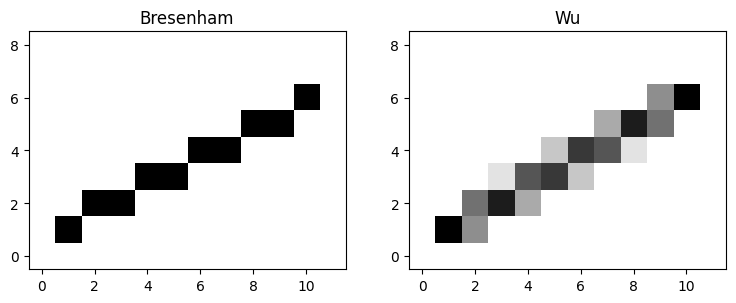

In [8]:
hard = rasterize(bresenham(1, 1, 10, 6), (9, 12))
soft = rasterize_wu(samples, (9, 12))

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(hard, origin="lower", cmap="gray_r", vmin=0, vmax=1)
ax[0].set_title("Bresenham")
ax[1].imshow(soft, origin="lower", cmap="gray_r", vmin=0, vmax=1)
ax[1].set_title("Wu")
plt.show()

<div dir="rtl">

## تمرین

- خط دیگری انتخاب کنید (مثلاً با شیب تند یا منفی) و خروجی `bresenham` را با `dda` مقایسه کنید.
- `wu_line` را طوری تغییر دهید که شیب بیشتر از ۱ را هم پوشش دهد.

</div>